**Neural Network + T3: 1 Wide Hidden Layer (256)**

This notebook trains **MLP with transformation T3** for 6 values of `alpha` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Neural network** (`MLPClassifier`): each hidden layer computes $h = \text{ReLU}(W x + b)$, where ReLU sets negatives to 0, and the output layer gives $P(\text{attack})$. The hidden layers **learn their own features**, so for the MLP the architecture plays the role of the transformation.

**Regularization:** sklearn adds an L2 penalty on all weights to the log-loss:

$$\text{log-loss} + \frac{\alpha}{2} \lVert W \rVert^2$$

Here it's the other way around from `C`: **large `alpha` ---> strong regularization** (small weights, smoother function), **small `alpha` ---> weak regularization**. We also use `early_stopping=True`: 10% of the training rows are held out inside the MLP, and training stops when the score on them stops improving. This is a second form of regularization.

**1. Setup**

In [11]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The architecture: 1 wide hidden layer (256)**

This network is **shallow but wide**: one layer of 256 neurons, each a learned combination of the 73 inputs. It has almost the same number of parameters as T2 (128, 64, 32), so comparing the two tells us whether depth or width helps more on this data.

**Why do we do this?**: Same model size as T2 ---> isolates the effect of deep vs wide

In [12]:
LAYERS = (256,)
n_in = build_preprocessor().fit(X_train).transform(X_train.head(1)).shape[1]
sizes = [n_in, *LAYERS, 1]

for a, b in zip(sizes, sizes[1:]):
    print(f"{a:>4} ---> {b:<4}: {a * b + b:>6,} parameters")
print("total:", sum(a * b + b for a, b in zip(sizes, sizes[1:])))

  73 ---> 256 : 18,944 parameters
 256 ---> 1   :    257 parameters
total: 19201


This network has 19,201 parameters, only about 3% fewer than the deep one in T2 (19,841), so the two really are about the same size. The difference is where the parameters go. Here almost all of them (18,944, or 98.7%) are in the single hidden layer, where each of the 256 neurons looks at all 73 inputs directly. In the deep network, only the first layer sees the inputs, and the later layers build combinations of combinations.

So this is basically the question: does our data need those "features of features", or is one big layer of direct combinations enough? Since the parameter counts are almost the same, whatever difference we see should come from the shape of the network, not its size.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> MLP with one hidden layer of 256.

**MLP settings:** we kept sklearn's defaults for everything except the architecture and `alpha`:

| Setting | Value |
|---|---|
| Hidden activation | ReLU |
| Output | sigmoid (gives $P(\text{attack})$) |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 200 |
| Early stopping | 10% of training held out, stop after 10 epochs without improvement |
| Random state | 42 |

We kept ReLU ($\max(0, z)$), the same as in T2 (128, 64, 32). With only one hidden layer, vanishing gradients aren't really a concern here, but using the same activation and settings in both networks means the only thing that changes between T2 and T3 is the architecture, so the deep vs wide comparison stays fair.

In [13]:
def build(alpha):
    return make_pipeline(build_preprocessor(),
                         MLPClassifier(hidden_layer_sizes=LAYERS, alpha=alpha,
                                       early_stopping=True, random_state=RANDOM_STATE))

**4. Regularization sweep**

We train one model for each of the 6 values of `alpha` (larger `alpha` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [14]:
GRID = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "MLP", "T3", "alpha", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"alpha={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

alpha=1e-05: val F1 = 0.9207, fit time = 4.58s
alpha=0.0001: val F1 = 0.9213, fit time = 3.24s
alpha=0.001: val F1 = 0.9210, fit time = 3.8s
alpha=0.01: val F1 = 0.9223, fit time = 3.12s
alpha=0.1: val F1 = 0.9188, fit time = 3.73s
alpha=1: val F1 = 0.9169, fit time = 4.71s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.0000,0.9100,0.9520,0.9305,0.1014,0.9012,0.9412,0.9207,0.1111,4.58,True,0.0098
1,0.0001,0.9019,0.9543,0.9274,0.1117,0.8975,0.9463,0.9213,0.1163,3.24,True,0.0061
2,0.0010,0.9083,0.9524,0.9298,0.1035,0.9015,0.9415,0.9210,0.1107,3.80,True,0.0088
3,0.0100,0.9021,0.9537,0.9272,0.1113,0.8972,0.9489,0.9223,0.1170,3.12,True,0.0049
4,0.1000,0.9047,0.9484,0.9260,0.1075,0.9018,0.9363,0.9188,0.1097,3.73,True,0.0073
5,1.0000,0.8651,0.9764,0.9174,0.1639,0.8664,0.9736,0.9169,0.1616,4.71,True,0.0005


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

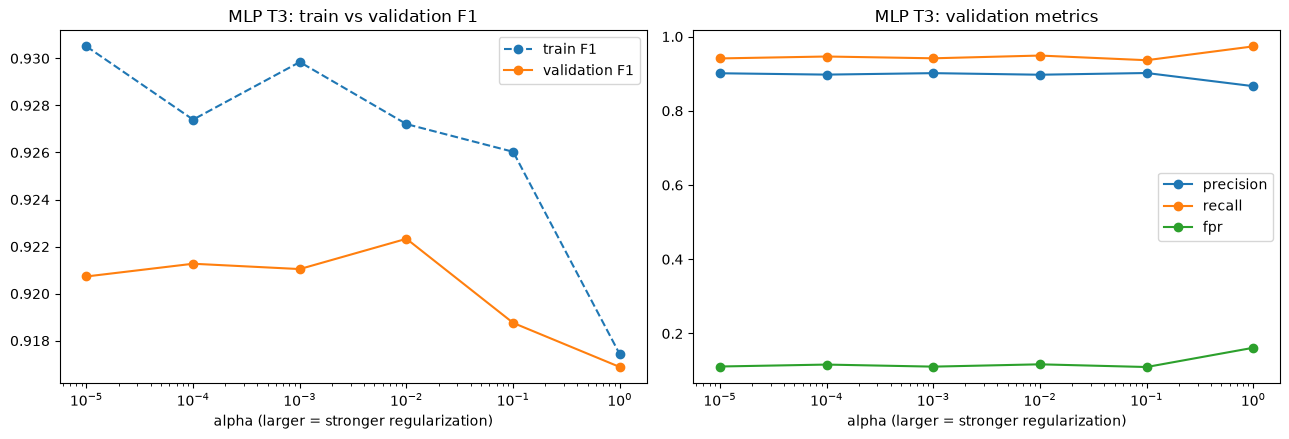

In [15]:
plot_sweep(results, "MLP T3", FIGS / "curve_mlp_t3_wide.png")

How did training go for each `alpha`? Left: the training loss per epoch. Right: the score on the 10% held out for early stopping. Training stops 10 epochs after that score stops improving.

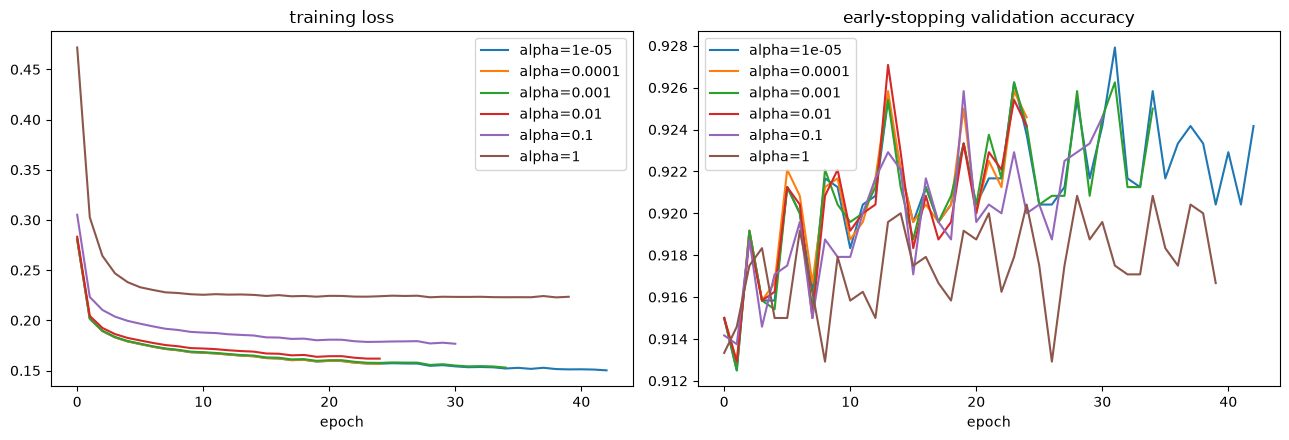

{'1e-05': 43, '0.0001': 25, '0.001': 35, '0.01': 25, '0.1': 31, '1': 40} <--- epochs trained per alpha


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for value, pipe in fitted.items():
    mlp = pipe[-1]
    axes[0].plot(mlp.loss_curve_, label=f"alpha={value:g}")
    axes[1].plot(mlp.validation_scores_, label=f"alpha={value:g}")
axes[0].set_title("training loss")
axes[1].set_title("early-stopping validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

print({f"{v:g}": p[-1].n_iter_ for v, p in fitted.items()}, "<--- epochs trained per alpha")

For small `alpha` (0.00001 up to 0.01), validation F1 barely moves: it stays between 0.9207 and 0.9223. The best is `alpha` = 0.01 at 0.9223, right in the middle of the grid this time. Past that point, more regularization starts to hurt: F1 drops to 0.9188 at `alpha` = 0.1 and 0.9169 at `alpha` = 1.

`alpha` = 1 is a clear case of **underfitting**. Training F1 falls from about 0.927 to 0.917 and ends up basically equal to validation (a gap of only 0.0005), so the model is doing equally badly on both. You can see it in the loss curves too: the training loss levels off around 0.22 instead of 0.15, and its early-stopping accuracy stays below all the other runs the whole time. The over-regularized model also gets much more trigger-happy: recall goes up to 0.974, but FPR jumps to 0.162 and precision drops to 0.866.

On the other side, we don't see much overfitting even with almost no regularization. The train/validation gap is never bigger than 0.01, so early stopping is probably already doing most of the regularization work here.

Compared with the deep network (T2), the wide one is better at almost every `alpha`: 0.9207 to 0.9223 here vs 0.9135 to 0.9174 there for the small values. Its best F1 is also higher (0.9223 vs 0.9185).

**Why does this matter?**: Since both networks have almost the same number of parameters, this suggests our flow features don't need deep "features of features" ---> one wide layer of direct combinations works better. We should be a bit careful though, since this is one split and one random seed, and the gap (about 0.004) is not huge.

**6. The best setting**

We pick the `alpha` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [17]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best alpha = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best alpha = 0.01: val F1 = 0.9223, precision = 0.8972, recall = 0.9489, FPR = 0.1170


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

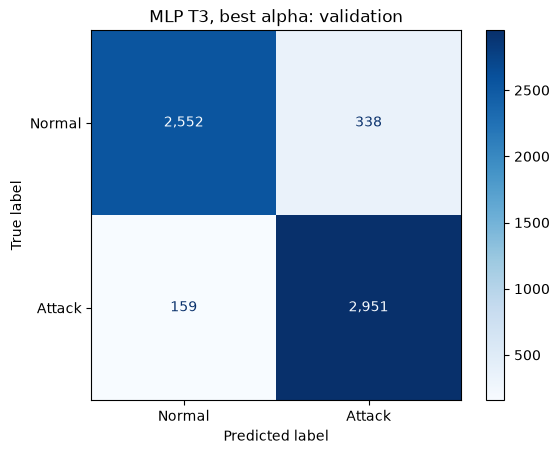

In [18]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("MLP T3, best alpha: validation")
plt.savefig(FIGS / "confusion_mlp_t3_wide.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [19]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,765,134,0.851
Analysis,89,83,6,0.933
Exploits,1105,1091,14,0.987
Backdoor,85,84,1,0.988
DoS,212,211,1,0.995
Reconnaissance,419,417,2,0.995
Generic,233,232,1,0.996
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


The best model (`alpha` = 0.01) makes 338 false alarms (11.7% of normal flows) and misses 159 attacks (5.1%). That's the best result of all our T2/T3 models so far. The false alarms are about the same as the deep network (340) and LR T3 (335), but it misses about 20 to 30 fewer attacks.

Most of that improvement comes from Fuzzers. This model misses 134 of them (recall 85.1%), compared with 152 for the deep network and 154 for LR T3. Fuzzers are still the weak spot though, and still make up 84% of all missed attacks. Every other type is caught at 93% or better.

It's interesting that the wide network catches more Fuzzers than the other flexible models, but it's still not far from Victoria's plain logistic regression (T0, 129 missed). So no matter which model we use, somewhere around 130 to 155 Fuzzers get through. That fits what the EDA told us: these attacks look like normal traffic in the flow features, so there's only so much any model can do with them.

**7. Save the results**

We save the 6 rows to `results/mlp_t3_wide.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [20]:
results.to_csv(RESULTS / "mlp_t3_wide.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "mlp_t3_wide.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/mlp_t3_wide.csv
